<h1 style="color:#041E42; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">
  <img src="https://upload.wikimedia.org/wikipedia/en/thumb/7/7a/University_of_Edinburgh_ceremonial_roundel.svg/360px-University_of_Edinburgh_ceremonial_roundel.svg.png" 
       style="vertical-align:middle; margin-right:10px; width:2em;" />
  The University of Edinburgh
</h1>

<h2 style="color:#005EB8; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">MSc Data Science for Health and Social Care </h2>

<div style="border-left:6px solid #005EB8; background:#F5F9FC; padding:0.8em; border-radius:6px; margin:1em 0;">
  <b>Module:</b> Foundations of Machine Learning  

  <b>Course Organiser:</b> Mr Christopher Aldous Oldnall  
</div>

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#FFF7E6;
  border-left:6px solid #F4A261;
  padding:1.3em 1.4em;
  border-radius:10px;
  margin-top:1.5em;
  margin-bottom:2em;
  max-width:900px;
">
  <h2 style="margin-top:0;">🚶‍♂️ Tutorial 2: How modelling choices affect prediction of step counts from trial data</h2>

  <p>
    In this tutorial, you will work with data from a randomised controlled trial designed to
    increase physical activity through daily text message prompts. The outcome of interest is
    the average number of daily steps recorded during the trial period.
  </p>

  <p>
    The aim of this session is <strong>not</strong> to identify a single “best” model, but to explore
    how different modelling choices influence predictions, interpretation, and real-world
    conclusions drawn from the same dataset.
  </p>

  <p>
    You will be asked to actively modify predictors, model complexity, and regularisation
    settings, and to reflect on how these changes affect both model performance and practical
    implications.
  </p>

  <p>
    The tutorial follows a realistic data analysis workflow:
  </p>

  <ul>
    <li>Inspecting and preparing trial data for analysis</li>
    <li>Exploring relationships between predictors and outcomes</li>
    <li>Fitting and comparing multiple regression models</li>
    <li>Evaluating performance using training–test splits and cross-validation</li>
    <li>Interpreting results in context, beyond numerical metrics alone</li>
  </ul>

  <p>
    Throughout the notebook, you will encounter <strong>task blocks</strong> that prompt you to
    experiment with the data and models, followed by reflective questions that ask you to explain
    <em>why</em> certain behaviours or results occur.
  </p>

  <p style="margin-bottom:0;">
    By the end of this tutorial, you should be able to justify modelling decisions, recognise
    trade-offs between accuracy and interpretability, and explain the implications of your
    choices to a non-technical audience.
  </p>
</div>

__Pair programming shared link__

Run the following cell without changing it. It only works on Noteable.

In [ ]:
! printf "\n\nLink below can be send to someone to share your Noteable session:\n\nhttps://noteable.edina.ac.uk/user/$(jupyter notebook list | grep -oP '(?<=user\/).*(?=\/\?)' )/lab?token=$( jupyter notebook list | grep -oP '(?<=token=).*(?= ::)' )\n\n"

In [7]:
# Uncomment the below if you haven't already installed the packages 
# !pip install pandas numpy matplotlib seaborn scikit-learn

In [8]:
# 📦 Standard package loading.
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.edgecolor": "#041E42",
    "axes.labelcolor": "#041E42",
    "xtick.color": "#041E42",
    "ytick.color": "#041E42",
    "text.color": "#041E42"
})

print("✅ Standard packages loaded and plotting style set to Edinburgh pallete")

✅ Standard packages loaded and plotting style set to Edinburgh pallete


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">📊 Task 1 — Visualise relationships between predictors and step count</h3>

  <p>
    Before fitting any models, explore how the outcome variable (daily step count) relates to
    the available predictors.
  </p>

  <ul>
    <li>Create visualisations showing step count against at least three different predictors</li>
    <li>Use appropriate plots (e.g. scatter plots, boxplots, or grouped summaries)</li>
    <li>Look for non-linear patterns, clusters, or outliers</li>
  </ul>

  <p>
    You are not trying to prove anything at this stage. The goal is to develop an intuition for
    which variables may be informative and how relationships might deviate from strict linearity.
  </p>
</div>

In [9]:
RCT_df = pd.read_csv("../data/week2/syntheticRCT_ISHSC_2023.csv")

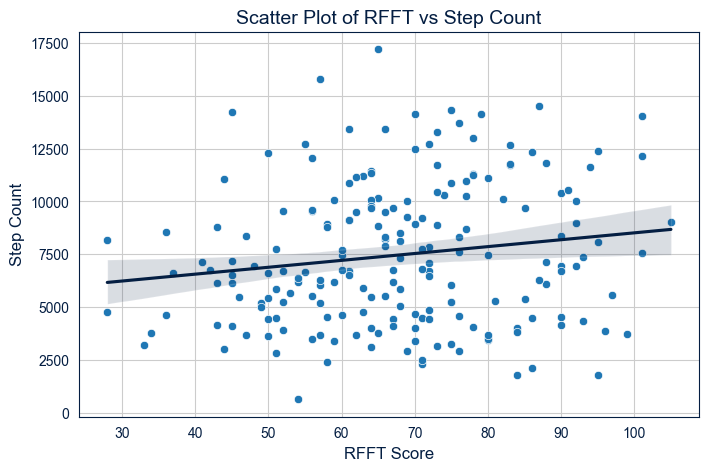

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(RCT_df, x="RFFT", y="step_count")
sns.regplot(RCT_df, x="RFFT", y="step_count", scatter=False, color="#041E42")
plt.title("Scatter Plot of RFFT vs Step Count")
plt.xlabel("RFFT Score")
plt.ylabel("Step Count")
plt.show()

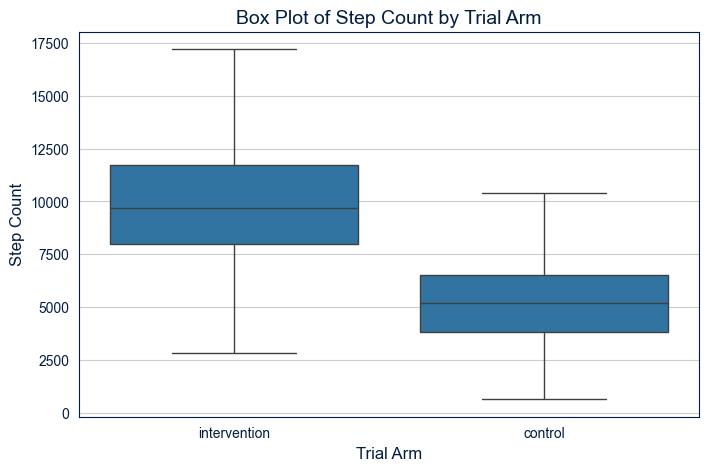

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(RCT_df, x="trial_arm", y="step_count")
plt.title("Box Plot of Step Count by Trial Arm")
plt.xlabel("Trial Arm")
plt.ylabel("Step Count")
plt.show()

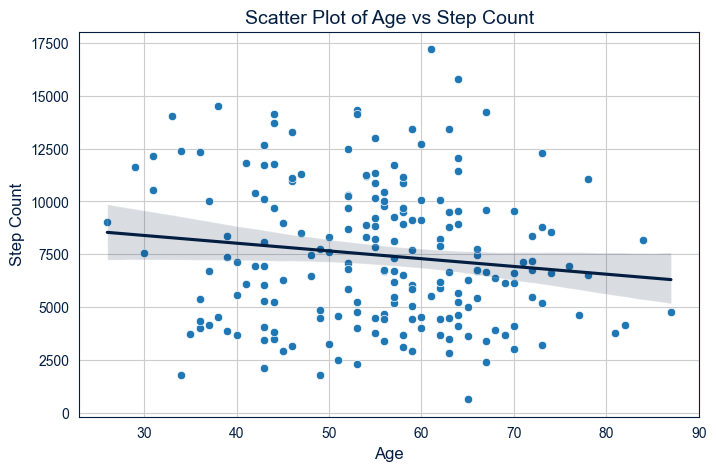

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(RCT_df, x="age", y="step_count")
sns.regplot(RCT_df, x="age", y="step_count", scatter=False, color="#041E42")
plt.title("Scatter Plot of Age vs Step Count")
plt.xlabel("Age")
plt.ylabel("Step Count")
plt.show()

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">📈 Task 2 — Investigate the effect of polynomial degree</h3>

  <p>
    Linear models assume straight-line relationships between predictors and outcomes.
    In this task, you will explore whether allowing non-linear terms improves performance.
  </p>

  <ul>
    <li>One-hot encode the categorical variables.</li>
    <li>Split the data into a sensible test and train set.</li>
    <li>Fit polynomial regression models with increasing degree (e.g. 1, 2, 3, 5).</li>
    <li>Compare training and test performance across degrees.</li>
    <li>Look for evidence of overfitting.</li>
  </ul>

  <p>
    Starter code is provided below to help you construct polynomial features.
  </p>
</div>

In [13]:
# INSERT CODE HERE: Create a new DataFrame with dummy variables for the categorical predictors and select X and y.
RCT_df_model = pd.get_dummies(
    RCT_df,
    columns = ["sex", "location", "baseline_exercise", "trial_arm"],
    drop_first = True
)
X = RCT_df_model.drop(columns=["step_count", "ID"])
y = RCT_df_model["step_count"]

In [14]:
# INSERT CODE HERE: Import the test/train split function and split the data into training and testing sets.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [15]:
# INSERT CODE HERE: Import PolynomialFeatures, LinearRegression, Pipeline, r2_score and mean_squared_error from sklearn.
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [16]:
# INSERT CODE HERE: Run a loop to fit polynomial regression models of degree 1, 2, 3 and 5 to the training data and evaluate their performance on the test set.
results = []
for degree in [2, 3, 4, 5]:
    poly_reg = Pipeline([
        ("poly_features", PolynomialFeatures(degree=degree, include_bias=False)),
        ("lin_reg", LinearRegression())
    ])
    poly_reg.fit(X_train, y_train)
    preds = poly_reg.predict(X_test)
    results.append({
        "Degree" : degree,
        "RMSE" : np.sqrt(mean_squared_error(y_test, preds)),
        "R2" : r2_score(y_test, preds)
    })

results_df = pd.DataFrame(results)
print(results_df)

   Degree           RMSE            R2
0       2    2583.907149      0.383942
1       3    5601.625831     -1.895315
2       4  394747.998679 -14377.299825
3       5  126458.715528  -1474.588270


In [17]:
# RUN THE CODE BELOW: Investigate which predictors were created from the original predictors in the best performing model.
best_degree = results_df.loc[results_df["RMSE"].idxmin(), "Degree"]
best_model = Pipeline([
    ("poly_features", PolynomialFeatures(degree=best_degree, include_bias=False)),
    ("lin_reg", LinearRegression())
])
best_model.fit(X_train, y_train)
feature_names = best_model.named_steps["poly_features"].get_feature_names_out(X.columns)
print("Best Performing Model Degree:", best_degree)
print("Predictor Names in Best Model:")
for name in feature_names:
    print(name)

Best Performing Model Degree: 2
Predictor Names in Best Model:
age
RFFT
sex_M
location_suburban
location_urban
baseline_exercise_moderate
baseline_exercise_vigorous
trial_arm_intervention
age^2
age RFFT
age sex_M
age location_suburban
age location_urban
age baseline_exercise_moderate
age baseline_exercise_vigorous
age trial_arm_intervention
RFFT^2
RFFT sex_M
RFFT location_suburban
RFFT location_urban
RFFT baseline_exercise_moderate
RFFT baseline_exercise_vigorous
RFFT trial_arm_intervention
sex_M^2
sex_M location_suburban
sex_M location_urban
sex_M baseline_exercise_moderate
sex_M baseline_exercise_vigorous
sex_M trial_arm_intervention
location_suburban^2
location_suburban location_urban
location_suburban baseline_exercise_moderate
location_suburban baseline_exercise_vigorous
location_suburban trial_arm_intervention
location_urban^2
location_urban baseline_exercise_moderate
location_urban baseline_exercise_vigorous
location_urban trial_arm_intervention
baseline_exercise_moderate^2
base

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">📐 Task 3 — Quantify multicollinearity using Variance Inflation Factors (VIF)</h3>

  <p>
    Multicollinearity can undermine the interpretability and stability of regression models.
    In this task, you will quantify the extent to which predictors are linearly related.
  </p>

  <ul>
    <li>Compute the Variance Inflation Factor (VIF) for each predictor</li>
    <li>Identify variables with unusually high VIF values</li>
    <li>Consider what a high VIF implies for coefficient estimates</li>
  </ul>

  <p>
    Do not remove any variables yet — this task is purely diagnostic.
  </p>
  </div>

In [18]:
# INSERT CODE HERE: Load the variance_inflation_factor function from statsmodels and force all predictors to be of type float.
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = X.astype(float)

In [19]:
# INSERT CODE HERE: Create a new DataFrame with the VIF values for each predictor and print it out.
vif_df = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i)
            for i in range(X.shape[1])]
})

vif_df

,Variable,VIF
0,age,7.733627
1,RFFT,7.047715
2,sex_M,2.149352
3,location_suburban,2.006867
4,location_urban,2.263932
5,baseline_exercise_moderate,1.856823
6,baseline_exercise_vigorous,1.902603
7,trial_arm_intervention,2.036950


In [20]:
# INSERT CODE HERE: Drop one of the predictors with a VIF value that is large and re-calculate the VIF values for the remaining predictors.
low_vif_vars = X.drop(columns="RFFT").columns.tolist()
X_low_vif = X[low_vif_vars]
vif_df_low = pd.DataFrame({
    "Variable": X_low_vif.columns,
    "VIF": [variance_inflation_factor(X_low_vif.values, i)
            for i in range(X_low_vif.shape[1])]
})

vif_df_low

,Variable,VIF
0,age,5.776657
1,sex_M,2.090575
2,location_suburban,1.857367
3,location_urban,2.070728
4,baseline_exercise_moderate,1.831287
5,baseline_exercise_vigorous,1.893035
6,trial_arm_intervention,1.925827


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">🧹 Task 4 — Fit a model after addressing multicollinearity</h3>

  <p>
    Using the VIF results from Task 2, construct a reduced predictor set by excluding variables
    with high multicollinearity.
  </p>

  <ul>
    <li>Select a threshold for what you consider “high” VIF</li>
    <li>Refit a set regression models (Linear and Elastic Net at least) using the reduced predictor set</li>
  </ul>

  <p>
    There is no single correct threshold — justify your choice.
  </p>
</div>

In [21]:
# INSERT CODE HERE: Create a list of predictors below your chosen VIF threshold, call this low_vif_vars (this is important for later).
low_vif_vars = vif_df.loc[vif_df["VIF"] < 5, "Variable"].tolist()

In [22]:
# INSERT CODE HERE: Import additional packages for models you wish to run (consider linear_model, preprocessing, model_selection and metrics from sklearn).
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

In [23]:
# INSERT CODE HERE: Fit your linear regression models here.
model_reduced = LinearRegression()
model_reduced.fit(X_train[low_vif_vars], y_train)

enet_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("enet", ElasticNet(max_iter=5000))
])

enet_params = {
    "enet__alpha":np.logspace(-3, 3, 50),
    "enet__l1_ratio":np.linspace(0.1, 0.9, 9)
}

enet_cv = GridSearchCV(enet_reg, enet_params, scoring="neg_root_mean_squared_error", cv=5)

enet_cv.fit(X_train[low_vif_vars], y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=5000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'enet__alpha': array([1.0000...00000000e+03]), 'enet__l1_ratio': array([0.1, 0....7, 0.8, 0.9])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and paramete

In [24]:
# INSERT CODE HERE: Generate predictions and evaluate the performance of all models on the test set.
models = {
    "Linear" : model_reduced,
    "Elastic_Net" : enet_cv.best_estimator_
}

results = []

for name, model in models.items():
    preds = model.predict(X_test[low_vif_vars])
    results.append({
        "Model" : name,
        "RMSE" : np.sqrt(mean_squared_error(y_test, preds)),
        "R2" : r2_score(y_test, preds)
    })

results_df = pd.DataFrame(results)
results_df

,Model,RMSE,R2
0,Linear,2464.537990,0.439548
1,Elastic_Net,2468.423687,0.437779


In [25]:
# RUN THE CODE BELOW: This retrieves which predictors were retained for each model in models.
for name, model in models.items():
    # Case 1: plain LinearRegression
    if hasattr(model, "coef_"):
        coef = model.coef_
        features = X_train[low_vif_vars].columns
    # Case 2: Pipeline
    else:
        final_estimator = model.steps[-1][1]
        coef = final_estimator.coef_
        features = X_train[low_vif_vars].columns
    coef_series = pd.Series(coef, index=features)
    print(f"\n{name} coefficients:")
    print(coef_series[coef_series != 0])


Linear coefficients:
sex_M                         -310.785761
location_suburban             -242.890526
location_urban                 -52.670827
baseline_exercise_moderate     538.688029
baseline_exercise_vigorous     280.899551
trial_arm_intervention        4551.649442
dtype: float64

Elastic_Net coefficients:
sex_M                         -137.267255
location_suburban             -106.765490
location_urban                   0.508786
baseline_exercise_moderate     193.564102
baseline_exercise_vigorous      91.413147
trial_arm_intervention        2084.727092
dtype: float64


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">🧠 Task 5 — Interpret model behaviour and results</h3>

  <p>
    Reflect on the models you have fitted so far.
  </p>

  <ul>
    <li>Which predictors appear most influential?</li>
    <li>How stable are coefficient estimates across models?</li>
    <li>What trade-offs do you observe between complexity and interpretability?</li>
  </ul>

  <p>
    Your answers should reference both numerical results and modelling assumptions.
  </p>
</div>

The variance inflation factor (VIF) analysis suggests that most predictors in the model exhibit low to moderate multicollinearity, with VIF values close to 2. These variables therefore contribute largely independent information, and their coefficient estimates are expected to be relatively stable. Two predictors, age and RFFT, show elevated VIF values above the chosen threshold, indicating notable multicollinearity. This suggests that these variables overlap substantially with other predictors in the model and that their individual coefficient estimates may be unstable if included simultaneously.

Importantly, elevated VIF values do not imply that both age and RFFT should be removed. Multicollinearity is a property of sets of variables rather than individual predictors, and removing both variables would be unnecessary and could lead to a loss of relevant information. Instead, retaining one of these variables, or excluding both from the reduced model used here, can improve interpretability without fundamentally altering the conclusions drawn from the remaining predictors.

Comparing coefficient estimates between the reduced linear model and the Elastic Net model provides further insight into the effects of multicollinearity and regularisation. In the linear model, coefficient magnitudes are generally larger, particularly for the intervention indicator and baseline exercise categories. For example, the estimated effect of being in the intervention arm is approximately 4,552 additional steps, whereas in the Elastic Net model this estimate is reduced to around 2,085 steps. This shrinkage reflects the penalty applied by Elastic Net, which discourages large coefficients when predictors provide overlapping information.

A similar pattern is observed across other predictors. Coefficients for sex and location are smaller in magnitude under Elastic Net than in the linear model, and the effect of living in an urban location is shrunk almost to zero. This suggests that, once correlations between predictors are accounted for, urban location contributes little independent predictive information. By contrast, baseline exercise level and trial arm remain clearly non-zero, indicating that these variables retain explanatory value even under regularisation.

Overall, these results highlight a key modelling trade-off. The linear model retains all predictors and may offer a more direct interpretation of coefficients, but its estimates are more sensitive to multicollinearity. The Elastic Net model sacrifices some interpretability in favour of stability, shrinking coefficients and down-weighting redundant predictors while preserving overall predictive structure. Neither approach is universally superior; the appropriate choice depends on whether the primary goal is explanation, stability, or prediction.

This comparison illustrates that modelling decisions should be guided by diagnostic evidence and substantive reasoning, rather than by mechanical rules or single performance metrics.


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

<div style="
  background:#F5F9FC;
  border-left:6px solid #0B4F6C;
  padding:1em 1.2em;
  border-radius:8px;
  margin-top:2em;
  max-width:850px;
">
  <h3 style="margin-top:0;">⚖️ Task 6 — Prediction vs estimation and limits of causal claims</h3>

  <p>
    In this final task, step back from the technical details and consider what your models can
    and cannot tell you.
  </p>

  <ul>
    <li>Explain the difference between prediction and estimation</li>
    <li>Discuss why strong predictive performance does not imply causality</li>
    <li>Relate your answer to the context of a randomised trial</li>
  </ul>

  <p>
    Focus on conceptual clarity rather than equations.
  </p>
</div>

The models fitted in this analysis serve different purposes, and it is important to distinguish clearly between prediction, estimation, and causal interpretation.

Prediction refers to the ability of a model to accurately forecast daily step counts for new individuals. From this perspective, model performance is judged primarily using out-of-sample metrics such as RMSE or R². A model may perform well predictively even if its internal structure is complex or difficult to interpret, as long as it generalises well to unseen data.

Estimation, by contrast, focuses on learning and interpreting the relationships between predictors and the outcome. In this context, regression coefficients are of central interest, as they describe how the expected step count changes with each predictor, holding others constant. Estimation places greater emphasis on coefficient stability, multicollinearity, and interpretability than on predictive accuracy alone.

Importantly, strong predictive performance does not imply that a model captures causal relationships. A model may predict well by exploiting correlations in the data that arise from confounding, measurement artefacts, or structural dependencies between predictors. Changes in model specification, such as removing correlated variables, can lead to substantial changes in coefficient estimates, highlighting that these coefficients are not inherently causal quantities.

Although the data arise from a randomised controlled trial, only variables that were directly randomised can be interpreted causally without further assumptions. Associations between non-randomised predictors (such as baseline characteristics) and step count remain observational, even within a trial setting. As a result, regression coefficients for these variables should be interpreted as conditional associations rather than causal effects.

Overall, this analysis demonstrates that predictive accuracy, interpretability, and causal validity are distinct goals. Regression models can be highly useful for prediction and description, but causal claims require careful attention to study design and cannot be justified by model fit alone.